In [1]:
import pandas as pd
import os

# Paths to datasets
data_path = "../data/raw/"

# Load datasets
electricity = pd.read_csv(data_path + "electricity_cleaned.csv")
solar = pd.read_csv(data_path + "solar_cleaned.csv")
weather = pd.read_csv(data_path + "weather.csv")
metadata = pd.read_csv(data_path + "metadata.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [2]:
datasets = {
    "Electricity": electricity,
    "Solar": solar,
    "Weather": weather,
    "Metadata": metadata
}

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("\nShape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    print(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())


ELECTRICITY

Shape:
(17544, 1579)

Columns:
['timestamp', 'Panther_parking_Lorriane', 'Panther_lodging_Cora', 'Panther_office_Hannah', 'Panther_lodging_Hattie', 'Panther_education_Teofila', 'Panther_education_Jerome', 'Panther_retail_Felix', 'Panther_parking_Asia', 'Panther_education_Misty', 'Panther_retail_Gilbert', 'Panther_office_Catherine', 'Panther_education_Tina', 'Panther_education_Janis', 'Panther_office_Patti', 'Panther_retail_Romeo', 'Panther_office_Lauretta', 'Panther_parking_Alaina', 'Panther_office_Valarie', 'Panther_lodging_Blaine', 'Panther_office_Karla', 'Panther_education_Quintin', 'Panther_assembly_Pamella', 'Panther_office_Graham', 'Panther_office_Larry', 'Panther_lodging_Jorge', 'Panther_education_Violet', 'Panther_lodging_Edison', 'Panther_office_Ruthie', 'Panther_lodging_Awilda', 'Panther_lodging_Gale', 'Panther_education_Edna', 'Panther_lodging_Kara', 'Panther_office_Garth', 'Panther_parking_Mellissa', 'Panther_assembly_Carrol', 'Panther_lodging_Jana', 'Panther_

In [3]:
print("ELECTRICITY SHAPE:", electricity.shape)
print("\nELECTRICITY FIRST 10 COLUMNS:")
print(electricity.columns[:10].tolist())

print("\nSOLAR BUILDING COLUMNS:")
print(solar.columns[1:].tolist())

print("\nMETADATA FIRST 10 BUILDING IDs:")
print(metadata["building_id"].head(10).tolist())

ELECTRICITY SHAPE: (17544, 1579)

ELECTRICITY FIRST 10 COLUMNS:
['timestamp', 'Panther_parking_Lorriane', 'Panther_lodging_Cora', 'Panther_office_Hannah', 'Panther_lodging_Hattie', 'Panther_education_Teofila', 'Panther_education_Jerome', 'Panther_retail_Felix', 'Panther_parking_Asia', 'Panther_education_Misty']

SOLAR BUILDING COLUMNS:
['Bobcat_education_Dylan', 'Bobcat_education_Alissa', 'Bobcat_education_Coleman', 'Bobcat_other_Timothy', 'Bobcat_office_Justine']

METADATA FIRST 10 BUILDING IDs:
['Panther_lodging_Dean', 'Panther_lodging_Shelia', 'Panther_lodging_Ricky', 'Panther_education_Rosalie', 'Panther_education_Misty', 'Panther_office_Daina', 'Panther_education_Mattie', 'Panther_office_Woodrow', 'Panther_education_Diann', 'Panther_education_Gina']


In [4]:
# Convert electricity data from wide format to long format

electricity_long = electricity.melt(
    id_vars="timestamp",
    var_name="building_id",
    value_name="electricity_consumption"
)

print("New shape:", electricity_long.shape)

print(electricity_long.head())

print("\nMissing values:")
print(electricity_long.isnull().sum())

New shape: (27684432, 3)
             timestamp               building_id  electricity_consumption
0  2016-01-01 00:00:00  Panther_parking_Lorriane                      0.0
1  2016-01-01 01:00:00  Panther_parking_Lorriane                      0.0
2  2016-01-01 02:00:00  Panther_parking_Lorriane                      0.0
3  2016-01-01 03:00:00  Panther_parking_Lorriane                      0.0
4  2016-01-01 04:00:00  Panther_parking_Lorriane                      0.0

Missing values:
timestamp                        0
building_id                      0
electricity_consumption    1504197
dtype: int64


In [5]:
# Remove rows where electricity consumption is missing

electricity_long = electricity_long.dropna(
    subset=["electricity_consumption"]
)

print("Shape after removing missing values:")
print(electricity_long.shape)

print("\nRemaining missing values:")
print(electricity_long.isnull().sum())

Shape after removing missing values:
(26180235, 3)

Remaining missing values:
timestamp                  0
building_id                0
electricity_consumption    0
dtype: int64


In [6]:
# Select useful metadata columns

metadata_selected = metadata[
    [
        "building_id",
        "site_id",
        "primaryspaceusage",
        "sqm",
        "numberoffloors",
        "yearbuilt",
        "occupants"
    ]
].copy()

print("Metadata selected shape:")
print(metadata_selected.shape)

print("\nMissing values:")
print(metadata_selected.isnull().sum())

print(metadata_selected.head())

Metadata selected shape:
(1636, 7)

Missing values:
building_id             0
site_id                 0
primaryspaceusage      21
sqm                     0
numberoffloors       1195
yearbuilt             819
occupants            1406
dtype: int64
                 building_id  site_id    primaryspaceusage    sqm  \
0       Panther_lodging_Dean  Panther  Lodging/residential  508.8   
1     Panther_lodging_Shelia  Panther  Lodging/residential  929.0   
2      Panther_lodging_Ricky  Panther  Lodging/residential  483.1   
3  Panther_education_Rosalie  Panther            Education  690.5   
4    Panther_education_Misty  Panther            Education  252.7   

   numberoffloors  yearbuilt  occupants  
0             NaN     1989.0        NaN  
1             NaN     1992.0        NaN  
2             NaN     2016.0        NaN  
3             NaN     2008.0        NaN  
4             NaN     2004.0        NaN  


In [7]:
# Keep only reliable metadata columns

metadata_selected = metadata[
    [
        "building_id",
        "site_id",
        "primaryspaceusage",
        "sqm"
    ]
].copy()

# Check missing values
print(metadata_selected.isnull().sum())

# Fill missing building usage with "Unknown"
metadata_selected["primaryspaceusage"] = (
    metadata_selected["primaryspaceusage"]
    .fillna("Unknown")
)

print("\nAfter handling missing values:")
print(metadata_selected.isnull().sum())

print("\nFirst 5 rows:")
print(metadata_selected.head())

building_id           0
site_id               0
primaryspaceusage    21
sqm                   0
dtype: int64

After handling missing values:
building_id          0
site_id              0
primaryspaceusage    0
sqm                  0
dtype: int64

First 5 rows:
                 building_id  site_id    primaryspaceusage    sqm
0       Panther_lodging_Dean  Panther  Lodging/residential  508.8
1     Panther_lodging_Shelia  Panther  Lodging/residential  929.0
2      Panther_lodging_Ricky  Panther  Lodging/residential  483.1
3  Panther_education_Rosalie  Panther            Education  690.5
4    Panther_education_Misty  Panther            Education  252.7


In [8]:
# Merge electricity data with building metadata

master_data = electricity_long.merge(
    metadata_selected,
    on="building_id",
    how="inner"
)

print("Master dataset shape:")
print(master_data.shape)

print("\nMissing values:")
print(master_data.isnull().sum())

print("\nFirst 5 rows:")
print(master_data.head())

Master dataset shape:
(26180235, 6)

Missing values:
timestamp                  0
building_id                0
electricity_consumption    0
site_id                    0
primaryspaceusage          0
sqm                        0
dtype: int64

First 5 rows:
             timestamp               building_id  electricity_consumption  \
0  2016-01-01 00:00:00  Panther_parking_Lorriane                      0.0   
1  2016-01-01 01:00:00  Panther_parking_Lorriane                      0.0   
2  2016-01-01 02:00:00  Panther_parking_Lorriane                      0.0   
3  2016-01-01 03:00:00  Panther_parking_Lorriane                      0.0   
4  2016-01-01 04:00:00  Panther_parking_Lorriane                      0.0   

   site_id primaryspaceusage      sqm  
0  Panther           Parking  36012.7  
1  Panther           Parking  36012.7  
2  Panther           Parking  36012.7  
3  Panther           Parking  36012.7  
4  Panther           Parking  36012.7  


In [9]:
# Check timestamp data types and date ranges

print("MASTER DATA")
print("Timestamp datatype:", master_data["timestamp"].dtype)
print("Date range:", master_data["timestamp"].min(), "to", master_data["timestamp"].max())
print("Unique sites:", master_data["site_id"].nunique())

print("\nWEATHER DATA")
print("Timestamp datatype:", weather["timestamp"].dtype)
print("Date range:", weather["timestamp"].min(), "to", weather["timestamp"].max())
print("Unique sites:", weather["site_id"].nunique())

# Check how many site IDs are common
common_sites = set(master_data["site_id"]).intersection(
    set(weather["site_id"])
)

print("\nCommon site IDs:", len(common_sites))
print("Sample common sites:", list(common_sites)[:10])

MASTER DATA
Timestamp datatype: str
Date range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00
Unique sites: 19

WEATHER DATA
Timestamp datatype: str
Date range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00
Unique sites: 19

Common site IDs: 19
Sample common sites: ['Shrew', 'Hog', 'Cockatoo', 'Bull', 'Swan', 'Crow', 'Eagle', 'Bobcat', 'Fox', 'Wolf']


In [10]:
# Convert timestamp columns to datetime

master_data["timestamp"] = pd.to_datetime(
    master_data["timestamp"]
)

weather["timestamp"] = pd.to_datetime(
    weather["timestamp"]
)

print("MASTER DATA timestamp type:", master_data["timestamp"].dtype)
print("WEATHER timestamp type:", weather["timestamp"].dtype)

MASTER DATA timestamp type: datetime64[us]
WEATHER timestamp type: datetime64[us]


In [11]:
# Select useful weather columns

weather_selected = weather[
    [
        "timestamp",
        "site_id",
        "airTemperature",
        "cloudCoverage",
        "dewTemperature",
        "seaLvlPressure",
        "windDirection",
        "windSpeed"
    ]
].copy()

print("Weather selected shape:", weather_selected.shape)

print("\nMissing values:")
print(weather_selected.isnull().sum())

print("\nFirst 5 rows:")
print(weather_selected.head())

Weather selected shape: (331166, 8)

Missing values:
timestamp              0
site_id                0
airTemperature       128
cloudCoverage     170987
dewTemperature       328
seaLvlPressure     21624
windDirection      13005
windSpeed            574
dtype: int64

First 5 rows:
            timestamp  site_id  airTemperature  cloudCoverage  dewTemperature  \
0 2016-01-01 00:00:00  Panther            19.4            NaN            19.4   
1 2016-01-01 01:00:00  Panther            21.1            6.0            21.1   
2 2016-01-01 02:00:00  Panther            21.1            NaN            21.1   
3 2016-01-01 03:00:00  Panther            20.6            NaN            20.0   
4 2016-01-01 04:00:00  Panther            21.1            NaN            20.6   

   seaLvlPressure  windDirection  windSpeed  
0             NaN            0.0        0.0  
1          1019.4            0.0        0.0  
2          1018.8          210.0        1.5  
3          1018.1            0.0        0.0  
4 

In [12]:
# Sort weather data by site and timestamp
weather_selected = weather_selected.sort_values(
    by=["site_id", "timestamp"]
)

# Weather columns to handle
weather_features = [
    "airTemperature",
    "cloudCoverage",
    "dewTemperature",
    "seaLvlPressure",
    "windDirection",
    "windSpeed"
]

# Forward fill and backward fill within each site
weather_selected[weather_features] = (
    weather_selected
    .groupby("site_id")[weather_features]
    .transform(lambda x: x.ffill().bfill())
)

print("Missing values after filling:")
print(weather_selected.isnull().sum())

Missing values after filling:
timestamp             0
site_id               0
airTemperature        0
cloudCoverage     33720
dewTemperature        0
seaLvlPressure    17500
windDirection         0
windSpeed             0
dtype: int64


In [13]:
# Fill remaining missing values using the overall median

weather_selected["cloudCoverage"] = weather_selected[
    "cloudCoverage"
].fillna(
    weather_selected["cloudCoverage"].median()
)

weather_selected["seaLvlPressure"] = weather_selected[
    "seaLvlPressure"
].fillna(
    weather_selected["seaLvlPressure"].median()
)

# Check again
print("Final missing values:")
print(weather_selected.isnull().sum())

Final missing values:
timestamp         0
site_id           0
airTemperature    0
cloudCoverage     0
dewTemperature    0
seaLvlPressure    0
windDirection     0
windSpeed         0
dtype: int64


In [14]:
# Merge master dataset with weather data

master_data = master_data.merge(
    weather_selected,
    on=["timestamp", "site_id"],
    how="left"
)

print("Final master dataset shape:")
print(master_data.shape)

print("\nMissing values:")
print(master_data.isnull().sum())

print("\nFirst 5 rows:")
print(master_data.head())

Final master dataset shape:
(26183113, 12)

Missing values:
timestamp                      0
building_id                    0
electricity_consumption        0
site_id                        0
primaryspaceusage              0
sqm                            0
airTemperature             88599
cloudCoverage              88599
dewTemperature             88599
seaLvlPressure             88599
windDirection              88599
windSpeed                  88599
dtype: int64

First 5 rows:
            timestamp               building_id  electricity_consumption  \
0 2016-01-01 00:00:00  Panther_parking_Lorriane                      0.0   
1 2016-01-01 01:00:00  Panther_parking_Lorriane                      0.0   
2 2016-01-01 02:00:00  Panther_parking_Lorriane                      0.0   
3 2016-01-01 03:00:00  Panther_parking_Lorriane                      0.0   
4 2016-01-01 04:00:00  Panther_parking_Lorriane                      0.0   

   site_id primaryspaceusage      sqm  airTemperature  clou

In [15]:
# Check duplicate timestamp + site_id combinations in weather

weather_duplicates = weather_selected.duplicated(
    subset=["timestamp", "site_id"]
).sum()

print("Duplicate weather timestamp + site_id rows:", weather_duplicates)


# Check how many master_data rows have no weather match

missing_weather_rows = master_data[
    master_data["airTemperature"].isna()
]

print("Rows without matching weather:", len(missing_weather_rows))

print("\nSample rows without weather:")
print(
    missing_weather_rows[
        ["timestamp", "building_id", "site_id"]
    ].head(10)
)

Duplicate weather timestamp + site_id rows: 37
Rows without matching weather: 88599

Sample rows without weather:
                 timestamp                building_id  site_id
1730   2016-03-13 02:00:00   Panther_parking_Lorriane  Panther
19050  2016-03-13 02:00:00       Panther_lodging_Cora  Panther
36450  2016-03-13 02:00:00      Panther_office_Hannah  Panther
53976  2016-03-13 02:00:00     Panther_lodging_Hattie  Panther
71510  2016-03-13 02:00:00  Panther_education_Teofila  Panther
88834  2016-03-13 02:00:00   Panther_education_Jerome  Panther
106231 2016-03-13 02:00:00       Panther_retail_Felix  Panther
123766 2016-03-13 02:00:00       Panther_parking_Asia  Panther
141301 2016-03-13 02:00:00    Panther_education_Misty  Panther
158827 2016-03-13 02:00:00     Panther_retail_Gilbert  Panther


In [16]:
# Check duplicate weather keys and remove them

weather_selected = weather_selected.drop_duplicates(
    subset=["timestamp", "site_id"],
    keep="first"
)

print("Weather shape after removing duplicates:")
print(weather_selected.shape)

print(
    "Remaining duplicates:",
    weather_selected.duplicated(
        subset=["timestamp", "site_id"]
    ).sum()
)

Weather shape after removing duplicates:
(331129, 8)
Remaining duplicates: 0


In [17]:
# Recreate clean master dataset without weather

master_data = electricity_long.merge(
    metadata_selected,
    on="building_id",
    how="inner"
)

print("Clean master shape:", master_data.shape)

Clean master shape: (26180235, 6)


In [18]:
# Check timestamp types
print("Master:", master_data["timestamp"].dtype)
print("Weather:", weather_selected["timestamp"].dtype)

Master: str
Weather: datetime64[us]


In [19]:
# Convert master_data timestamp back to datetime
master_data["timestamp"] = pd.to_datetime(master_data["timestamp"])

print("Master:", master_data["timestamp"].dtype)
print("Weather:", weather_selected["timestamp"].dtype)

Master: datetime64[us]
Weather: datetime64[us]


In [20]:
# Convert master_data timestamp back to datetime
master_data["timestamp"] = pd.to_datetime(master_data["timestamp"])

print("Master:", master_data["timestamp"].dtype)
print("Weather:", weather_selected["timestamp"].dtype)

Master: datetime64[us]
Weather: datetime64[us]


In [21]:
# Merge cleaned weather data
master_data = master_data.merge(
    weather_selected,
    on=["timestamp", "site_id"],
    how="left"
)

print("Master dataset shape:", master_data.shape)

print("\nMissing weather values:")
print(
    master_data[
        [
            "airTemperature",
            "cloudCoverage",
            "dewTemperature",
            "seaLvlPressure",
            "windDirection",
            "windSpeed"
        ]
    ].isnull().sum()
)

Master dataset shape: (26180235, 12)

Missing weather values:
airTemperature    88599
cloudCoverage     88599
dewTemperature    88599
seaLvlPressure    88599
windDirection     88599
windSpeed         88599
dtype: int64


In [22]:
weather_features = [
    "airTemperature",
    "cloudCoverage",
    "dewTemperature",
    "seaLvlPressure",
    "windDirection",
    "windSpeed"
]

# Fill missing weather values using median for each site
for col in weather_features:
    master_data[col] = master_data[col].fillna(
        master_data.groupby("site_id")[col].transform("median")
    )

# Final fallback: overall median
for col in weather_features:
    master_data[col] = master_data[col].fillna(
        master_data[col].median()
    )

print("Final missing values:")
print(master_data[weather_features].isnull().sum())

Final missing values:
airTemperature    0
cloudCoverage     0
dewTemperature    0
seaLvlPressure    0
windDirection     0
windSpeed         0
dtype: int64


In [23]:
master_data.to_pickle(
    "../data/processed/master_energy_weather.pkl"
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [24]:
master_data = pd.read_pickle(
    "../data/processed/master_energy_weather.pkl"
)

In [25]:
# Make sure solar timestamp is datetime
solar["timestamp"] = pd.to_datetime(solar["timestamp"])

# Convert solar data from wide format to long format
solar_long = solar.melt(
    id_vars="timestamp",
    var_name="building_id",
    value_name="solar_generation"
)

print("Solar long dataset shape:", solar_long.shape)

print("\nFirst 10 rows:")
print(solar_long.head(10))

print("\nMissing values:")
print(solar_long.isnull().sum())

Solar long dataset shape: (87720, 3)

First 10 rows:
            timestamp             building_id  solar_generation
0 2016-01-01 00:00:00  Bobcat_education_Dylan               0.0
1 2016-01-01 01:00:00  Bobcat_education_Dylan               0.0
2 2016-01-01 02:00:00  Bobcat_education_Dylan               0.0
3 2016-01-01 03:00:00  Bobcat_education_Dylan               0.0
4 2016-01-01 04:00:00  Bobcat_education_Dylan               0.0
5 2016-01-01 05:00:00  Bobcat_education_Dylan               0.0
6 2016-01-01 06:00:00  Bobcat_education_Dylan               0.0
7 2016-01-01 07:00:00  Bobcat_education_Dylan               0.0
8 2016-01-01 08:00:00  Bobcat_education_Dylan               0.0
9 2016-01-01 09:00:00  Bobcat_education_Dylan               0.0

Missing values:
timestamp               0
building_id             0
solar_generation    19055
dtype: int64


In [26]:
# Check solar data for each building

solar_summary = solar_long.groupby("building_id").agg(
    total_records=("solar_generation", "size"),
    missing_values=("solar_generation", lambda x: x.isna().sum()),
    non_missing_values=("solar_generation", lambda x: x.notna().sum()),
    min_generation=("solar_generation", "min"),
    max_generation=("solar_generation", "max"),
    mean_generation=("solar_generation", "mean")
)

print(solar_summary)

                          total_records  missing_values  non_missing_values  \
building_id                                                                   
Bobcat_education_Alissa           17544             397               17147   
Bobcat_education_Coleman          17544             373               17171   
Bobcat_education_Dylan            17544             371               17173   
Bobcat_office_Justine             17544           17544                   0   
Bobcat_other_Timothy              17544             370               17174   

                          min_generation  max_generation  mean_generation  
building_id                                                                
Bobcat_education_Alissa              0.0        262.1529        69.989592  
Bobcat_education_Coleman             0.0         16.2000         2.701757  
Bobcat_education_Dylan               0.0         27.7900         5.075233  
Bobcat_office_Justine                NaN             NaN          

In [27]:
# Remove buildings with completely missing solar data

solar_long = solar_long[
    solar_long["building_id"] != "Bobcat_office_Justine"
].copy()

print("New solar dataset shape:", solar_long.shape)

print("\nMissing values by building:")
print(
    solar_long.groupby("building_id")["solar_generation"]
    .apply(lambda x: x.isna().sum())
)

New solar dataset shape: (70176, 3)

Missing values by building:
building_id
Bobcat_education_Alissa     397
Bobcat_education_Coleman    373
Bobcat_education_Dylan      371
Bobcat_other_Timothy        370
Name: solar_generation, dtype: int64


In [28]:
# Sort solar data by building and timestamp
solar_long = solar_long.sort_values(
    by=["building_id", "timestamp"]
)

# Fill missing values using nearby readings within each building
solar_long["solar_generation"] = (
    solar_long
    .groupby("building_id")["solar_generation"]
    .transform(lambda x: x.ffill().bfill())
)

print("Remaining missing values:")
print(solar_long.isnull().sum())

Remaining missing values:
timestamp           0
building_id         0
solar_generation    0
dtype: int64


In [29]:
# Get the solar building IDs
solar_buildings = solar_long["building_id"].unique()

print("Solar buildings:")
print(solar_buildings)

# Check which solar buildings exist in master_data
master_buildings = set(master_data["building_id"].unique())

matched_buildings = [
    building for building in solar_buildings
    if building in master_buildings
]

print("\nMatched solar buildings:", len(matched_buildings))
print(matched_buildings)

Solar buildings:
<StringArray>
[ 'Bobcat_education_Alissa', 'Bobcat_education_Coleman',
   'Bobcat_education_Dylan',     'Bobcat_other_Timothy']
Length: 4, dtype: str

Matched solar buildings: 4
['Bobcat_education_Alissa', 'Bobcat_education_Coleman', 'Bobcat_education_Dylan', 'Bobcat_other_Timothy']


In [30]:
# Merge solar generation data with master dataset

master_data = master_data.merge(
    solar_long,
    on=["timestamp", "building_id"],
    how="left"
)

print("Final master dataset shape:")
print(master_data.shape)

print("\nMissing values:")
print(master_data.isnull().sum())

print("\nSolar data available:")
print(master_data["solar_generation"].notna().sum())

print("\nFirst rows with solar data:")
print(
    master_data[
        master_data["solar_generation"].notna()
    ].head()
)

Final master dataset shape:
(26180235, 13)

Missing values:
timestamp                         0
building_id                       0
electricity_consumption           0
site_id                           0
primaryspaceusage                 0
sqm                               0
airTemperature                    0
cloudCoverage                     0
dewTemperature                    0
seaLvlPressure                    0
windDirection                     0
windSpeed                         0
solar_generation           26114017
dtype: int64

Solar data available:
66218

First rows with solar data:
                   timestamp               building_id  \
18419716 2016-01-01 00:00:00  Bobcat_education_Coleman   
18419717 2016-01-01 01:00:00  Bobcat_education_Coleman   
18419718 2016-01-01 02:00:00  Bobcat_education_Coleman   
18419719 2016-01-01 03:00:00  Bobcat_education_Coleman   
18419720 2016-01-01 04:00:00  Bobcat_education_Coleman   

          electricity_consumption site_id primaryspa

In [31]:
# Create time-based features

master_data["hour"] = master_data["timestamp"].dt.hour

master_data["day_of_week"] = master_data["timestamp"].dt.dayofweek

master_data["month"] = master_data["timestamp"].dt.month

master_data["day"] = master_data["timestamp"].dt.day

master_data["year"] = master_data["timestamp"].dt.year

# Weekend indicator
master_data["is_weekend"] = (
    master_data["day_of_week"] >= 5
).astype(int)

print("Time-based features created successfully!")

print(
    master_data[
        [
            "timestamp",
            "hour",
            "day_of_week",
            "month",
            "day",
            "year",
            "is_weekend"
        ]
    ].head()
)

Time-based features created successfully!
            timestamp  hour  day_of_week  month  day  year  is_weekend
0 2016-01-01 00:00:00     0            4      1    1  2016           0
1 2016-01-01 01:00:00     1            4      1    1  2016           0
2 2016-01-01 02:00:00     2            4      1    1  2016           0
3 2016-01-01 03:00:00     3            4      1    1  2016           0
4 2016-01-01 04:00:00     4            4      1    1  2016           0


In [32]:
# Basic summary of electricity consumption

print("Electricity Consumption Summary:")
print(
    master_data["electricity_consumption"].describe()
)

print("\nBuilding Types:")
print(
    master_data["primaryspaceusage"].value_counts()
)

print("\nNumber of Buildings:")
print(
    master_data["building_id"].nunique()
)

print("\nNumber of Sites:")
print(
    master_data["site_id"].nunique()
)

Electricity Consumption Summary:
count    2.618024e+07
mean     1.382264e+02
std      2.532968e+02
min      0.000000e+00
25%      1.594800e+01
50%      5.457050e+01
75%      1.497800e+02
max      1.884574e+04
Name: electricity_consumption, dtype: float64

Building Types:
primaryspaceusage
Education                        9988191
Office                           5002058
Entertainment/public assembly    3380965
Public services                  2718990
Lodging/residential              2532445
Healthcare                        457658
Other                             431697
Parking                           396083
Warehouse/storage                 239122
Retail                            190614
Manufacturing/industrial          189691
Unknown                           166225
Services                          156563
Technology/science                109292
Food sales and service            104393
Utility                            65099
Religious worship                  51149
Name: count, 

In [33]:
# Average electricity consumption by hour

hourly_energy = (
    master_data.groupby("hour")["electricity_consumption"]
    .mean()
    .reset_index()
)

print(hourly_energy)

    hour  electricity_consumption
0      0               122.097797
1      1               120.121182
2      2               118.597775
3      3               117.701683
4      4               117.905571
5      5               120.761095
6      6               126.467740
7      7               134.007631
8      8               140.530462
9      9               146.503420
10    10               151.043147
11    11               154.096865
12    12               155.975227
13    13               157.229187
14    14               157.460380
15    15               156.761067
16    16               154.793224
17    17               150.863654
18    18               146.086553
19    19               142.068549
20    20               138.512881
21    21               134.293768
22    22               129.800197
23    23               125.124081


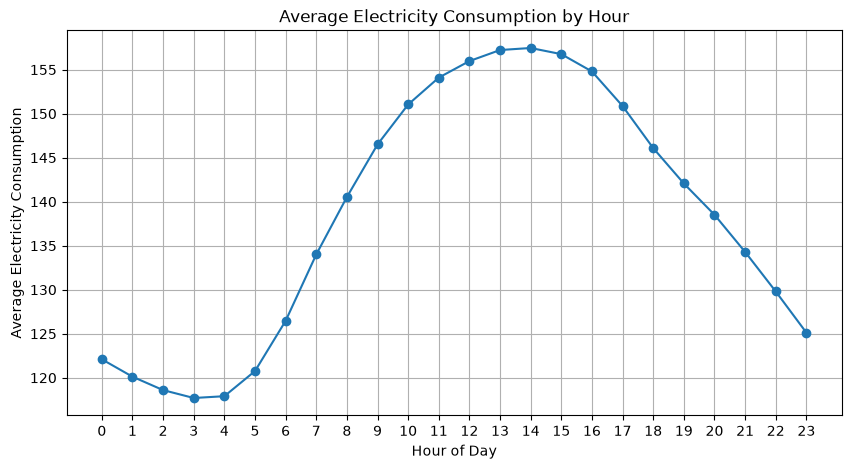

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_energy["hour"],
    hourly_energy["electricity_consumption"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Electricity Consumption")
plt.title("Average Electricity Consumption by Hour")

plt.xticks(range(24))
plt.grid()

plt.show()

In [35]:
# Average electricity consumption by month

monthly_energy = (
    master_data.groupby("month")["electricity_consumption"]
    .mean()
    .reset_index()
)

print(monthly_energy)

    month  electricity_consumption
0       1               133.828618
1       2               137.632562
2       3               133.593966
3       4               132.944263
4       5               133.694955
5       6               143.045376
6       7               145.833307
7       8               147.305636
8       9               147.395538
9      10               136.755585
10     11               135.093387
11     12               131.505647


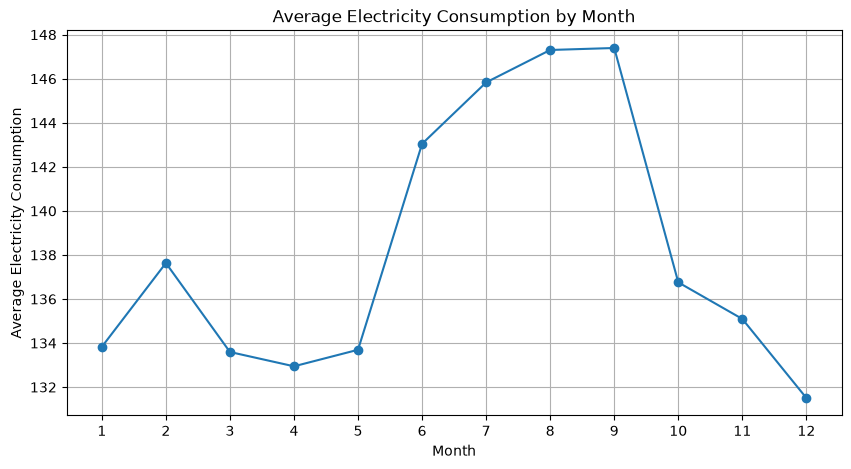

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_energy["month"],
    monthly_energy["electricity_consumption"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Electricity Consumption")
plt.title("Average Electricity Consumption by Month")

plt.xticks(range(1, 13))
plt.grid()

plt.show()

In [37]:
# Calculate important percentiles

percentiles = master_data["electricity_consumption"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

print("Electricity Consumption Percentiles:")
print(percentiles)

print("\nMaximum value:")
print(master_data["electricity_consumption"].max())

print("\nNumber of zero consumption records:")
print(
    (master_data["electricity_consumption"] == 0).sum()
)

Electricity Consumption Percentiles:
0.01       0.0000
0.05       0.0003
0.25      15.9480
0.50      54.5705
0.75     149.7800
0.95     556.4700
0.99    1211.1900
Name: electricity_consumption, dtype: float64

Maximum value:
18845.7369

Number of zero consumption records:
1115924


In [38]:
# Calculate the 99th percentile threshold

p99 = master_data["electricity_consumption"].quantile(0.99)

# Records above the 99th percentile
extreme_energy = master_data[
    master_data["electricity_consumption"] > p99
]

print("99th percentile threshold:", p99)

print("\nNumber of records above 99th percentile:")
print(len(extreme_energy))

print("\nTop 10 highest electricity consumption records:")

print(
    extreme_energy[
        [
            "timestamp",
            "building_id",
            "primaryspaceusage",
            "sqm",
            "electricity_consumption"
        ]
    ]
    .sort_values(
        by="electricity_consumption",
        ascending=False
    )
    .head(10)
)

99th percentile threshold: 1211.19

Number of records above 99th percentile:
261802

Top 10 highest electricity consumption records:
                   timestamp           building_id primaryspaceusage      sqm  \
18975777 2017-03-15 16:00:00    Swan_unknown_Rocco           Unknown   4779.2   
18974572 2017-01-24 08:00:00    Swan_unknown_Rocco           Unknown   4779.2   
19009568 2017-01-24 08:00:00   Swan_unknown_Jerold           Unknown   7746.6   
19063275 2017-03-15 16:00:00     Swan_unknown_Rudy           Unknown   6394.6   
18974068 2017-01-03 07:00:00    Swan_unknown_Rocco           Unknown   4779.2   
20670048 2016-08-11 10:00:00  Hog_education_Janell         Education  26718.3   
20677990 2017-07-12 14:00:00  Hog_education_Janell         Education  26718.3   
20677832 2017-07-05 14:00:00  Hog_education_Janell         Education  26718.3   
20678195 2017-07-22 15:00:00  Hog_education_Janell         Education  26718.3   
20677849 2017-07-06 13:00:00  Hog_education_Janell       

In [39]:
# Percentage of zero electricity consumption

zero_count = (
    master_data["electricity_consumption"] == 0
).sum()

zero_percentage = (
    zero_count / len(master_data)
) * 100

print("Zero consumption records:", zero_count)
print("Percentage of dataset:", round(zero_percentage, 2), "%")

# Check which building types have the most zero values
zero_by_usage = (
    master_data[
        master_data["electricity_consumption"] == 0
    ]
    .groupby("primaryspaceusage")
    .size()
    .sort_values(ascending=False)
)

print("\nZero consumption by building type:")
print(zero_by_usage.head(15))

Zero consumption records: 1115924
Percentage of dataset: 4.26 %

Zero consumption by building type:
primaryspaceusage
Education                        317719
Office                           257587
Entertainment/public assembly    250142
Lodging/residential              120101
Parking                           45462
Healthcare                        25643
Retail                            19915
Other                             18674
Public services                   18619
Warehouse/storage                 17748
Technology/science                10417
Unknown                            7044
Food sales and service             3458
Services                           1155
Manufacturing/industrial           1148
dtype: int64


In [40]:
from matplotlib.artist import np
# Create electricity consumption per square meter

master_data["energy_per_sqm"] = (
    master_data["electricity_consumption"] /
    master_data["sqm"]
)

print(
    master_data["energy_per_sqm"].describe()
)

print("\nMissing values:")
print(master_data["energy_per_sqm"].isnull().sum())

print("\nInfinite values:")
print(
    np.isinf(master_data["energy_per_sqm"]).sum()
)

count    2.618024e+07
mean     1.860999e-02
std      3.052372e-02
min      0.000000e+00
25%      5.828570e-03
50%      1.194364e-02
75%      2.200881e-02
max      3.943283e+00
Name: energy_per_sqm, dtype: float64

Missing values:
0

Infinite values:
0


In [41]:
# Check memory usage of the master dataset

memory_usage = (
    master_data.memory_usage(deep=True).sum()
    / (1024 ** 3)
)

print(f"Master dataset memory usage: {memory_usage:.2f} GB")

print("\nCurrent dataset shape:")
print(master_data.shape)

Master dataset memory usage: 7.80 GB

Current dataset shape:
(26180235, 20)


In [42]:
# Create a reproducible 1 million row sample for ML

ml_data = master_data.sample(
    n=1_000_000,
    random_state=42
).copy()

print("ML dataset shape:")
print(ml_data.shape)

print("\nMemory usage:")
print(
    round(
        ml_data.memory_usage(deep=True).sum() / (1024 ** 3),
        2
    ),
    "GB"
)

print("\nFirst 5 rows:")
print(ml_data.head())

ML dataset shape:
(1000000, 20)

Memory usage:
0.31 GB

First 5 rows:
                   timestamp             building_id  electricity_consumption  \
10688109 2016-09-10 15:00:00    Bear_education_Elise                 228.5563   
14798000 2016-07-19 00:00:00  Moose_education_Marlon                 137.7446   
23233685 2016-10-20 08:00:00     Eagle_office_Amanda                 254.1181   
11928235 2017-11-04 14:00:00   Lamb_education_Felipe                   9.3300   
10006739 2016-04-12 14:00:00     Bear_public_Orville                  59.3000   

         site_id primaryspaceusage      sqm  airTemperature  cloudCoverage  \
10688109    Bear         Education  20664.8            20.0            2.0   
14798000   Moose         Education  21000.0            18.8            0.0   
23233685   Eagle            Office   8487.9            16.7            2.0   
11928235    Lamb         Education   9005.0            11.0            0.0   
10006739    Bear   Public services   2700.0          

In [43]:
# Compare full dataset and ML sample

print("FULL DATASET")
print("Buildings:", master_data["building_id"].nunique())
print("Sites:", master_data["site_id"].nunique())
print("Building types:", master_data["primaryspaceusage"].nunique())

print("\nML SAMPLE")
print("Buildings:", ml_data["building_id"].nunique())
print("Sites:", ml_data["site_id"].nunique())
print("Building types:", ml_data["primaryspaceusage"].nunique())

print("\nAverage electricity consumption comparison:")
print("Full dataset:",
      round(master_data["electricity_consumption"].mean(), 2))

print("ML sample:",
      round(ml_data["electricity_consumption"].mean(), 2))

print("\nMedian electricity consumption comparison:")
print("Full dataset:",
      round(master_data["electricity_consumption"].median(), 2))

print("ML sample:",
      round(ml_data["electricity_consumption"].median(), 2))

FULL DATASET
Buildings: 1576
Sites: 19
Building types: 17

ML SAMPLE
Buildings: 1576
Sites: 19
Building types: 17

Average electricity consumption comparison:
Full dataset: 138.23
ML sample: 138.73

Median electricity consumption comparison:
Full dataset: 54.57
ML sample: 54.7


In [44]:
# Define target variable
y = ml_data["electricity_consumption"]

# Define input features
feature_columns = [
    "building_id",
    "site_id",
    "primaryspaceusage",
    "sqm",
    "airTemperature",
    "cloudCoverage",
    "dewTemperature",
    "seaLvlPressure",
    "windDirection",
    "windSpeed",
    "hour",
    "day_of_week",
    "month",
    "day",
    "year",
    "is_weekend"
]

# Create feature dataset
X = ml_data[feature_columns].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nMissing values in X:")
print(X.isnull().sum())

X shape: (1000000, 16)
y shape: (1000000,)

Selected features:
['building_id', 'site_id', 'primaryspaceusage', 'sqm', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'seaLvlPressure', 'windDirection', 'windSpeed', 'hour', 'day_of_week', 'month', 'day', 'year', 'is_weekend']

Missing values in X:
building_id          0
site_id              0
primaryspaceusage    0
sqm                  0
airTemperature       0
cloudCoverage        0
dewTemperature       0
seaLvlPressure       0
windDirection        0
windSpeed            0
hour                 0
day_of_week          0
month                0
day                  0
year                 0
is_weekend           0
dtype: int64


In [45]:
import numpy
import pandas
import sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 1.26.4
Pandas: 3.0.5
Scikit-learn: 1.9.0


In [46]:
from sklearn.preprocessing import LabelEncoder

# Categorical columns
categorical_columns = [
    "building_id",
    "site_id",
    "primaryspaceusage"
]

# Store encoders
label_encoders = {}

# Encode each categorical column
for column in categorical_columns:
    
    le = LabelEncoder()
    
    X[column] = le.fit_transform(X[column])
    
    label_encoders[column] = le

print("Categorical columns encoded successfully!")

print("\nFirst 5 rows:")
print(X.head())

print("\nData types:")
print(X.dtypes)

Categorical columns encoded successfully!

First 5 rows:
          building_id  site_id  primaryspaceusage      sqm  airTemperature  \
10688109           32        0                  0  20664.8            20.0   
14798000          995       10                  0  21000.0            18.8   
23233685          430        5                  6   8487.9            16.7   
11928235          891        9                  0   9005.0            11.0   
10006739           86        0                  9   2700.0            16.7   

          cloudCoverage  dewTemperature  seaLvlPressure  windDirection  \
10688109            2.0            13.3          1017.3          300.0   
14798000            0.0             9.5          1016.3          330.0   
23233685            2.0            10.6          1018.8           80.0   
11928235            0.0             7.0          1016.2          310.0   
10006739            2.0             8.3          1023.7          280.0   

          windSpeed  hour  da

In [47]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (800000, 16)
y_train: (800000,)

Testing data:
X_test: (200000, 16)
y_test: (200000,)


In [48]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

# Print results
print("Random Forest Model Performance")
print("-" * 40)

print(f"MAE:  {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R² Score: {r2_rf:.4f}")

Random Forest Model Performance
----------------------------------------
MAE:  16.0016
RMSE: 43.7283
R² Score: 0.9709


In [50]:
# Make predictions on test data
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 200000


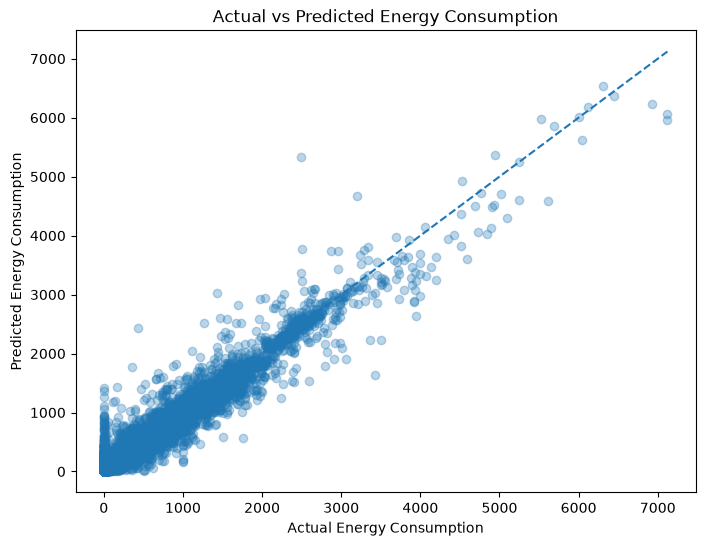

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("Actual vs Predicted Energy Consumption")

plt.show()

In [52]:
# Calculate residuals
residuals = y_test - y_pred

print("Mean Residual:", residuals.mean())
print("Minimum Residual:", residuals.min())
print("Maximum Residual:", residuals.max())

Mean Residual: -0.28494055307369226
Minimum Residual: -2840.3126404761892
Maximum Residual: 1784.052526598489


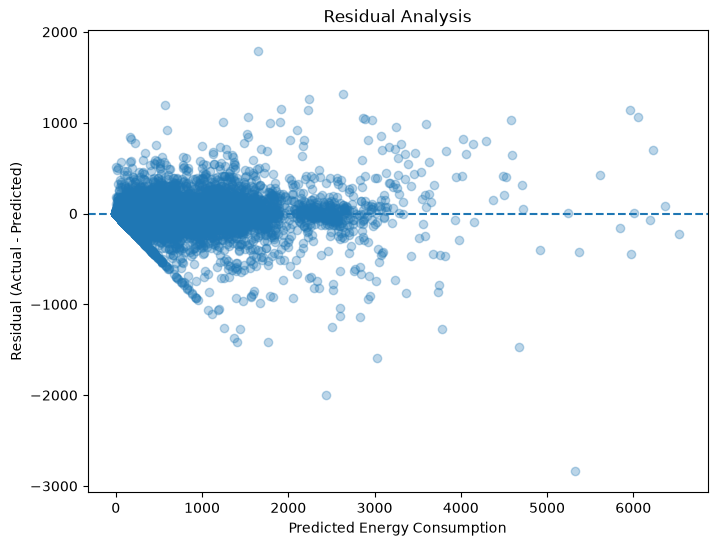

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.3)

# Zero-error reference line
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Energy Consumption")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")

plt.show()

In [54]:
# Calculate Random Forest residuals

residuals_rf = y_test - y_pred_rf

print("Residual Statistics")
print("-" * 40)

print("Mean Residual:", residuals_rf.mean())
print("Minimum Residual:", residuals_rf.min())
print("Maximum Residual:", residuals_rf.max())

Residual Statistics
----------------------------------------
Mean Residual: -0.28494055307369215
Minimum Residual: -2840.3126404761892
Maximum Residual: 1784.052526598489


In [55]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.2.0


In [56]:
from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=10,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=42
)

# Train the model
xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model training completed!")

XGBoost model training completed!


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Calculate evaluation metrics
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Model Performance")
print("-" * 40)

print(f"MAE:  {mae_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"R² Score: {r2_xgb:.4f}")

XGBoost Model Performance
----------------------------------------
MAE:  24.0176
RMSE: 52.5416
R² Score: 0.9581


In [58]:
# Calculate residuals for XGBoost
residuals_xgb = y_test - y_pred_xgb

print("XGBoost Residual Statistics")
print("-" * 40)

print("Mean Residual:", residuals_xgb.mean())
print("Minimum Residual:", residuals_xgb.min())
print("Maximum Residual:", residuals_xgb.max())

XGBoost Residual Statistics
----------------------------------------
Mean Residual: -0.14434651363471923
Minimum Residual: -2103.56455078125
Maximum Residual: 2122.409099609375


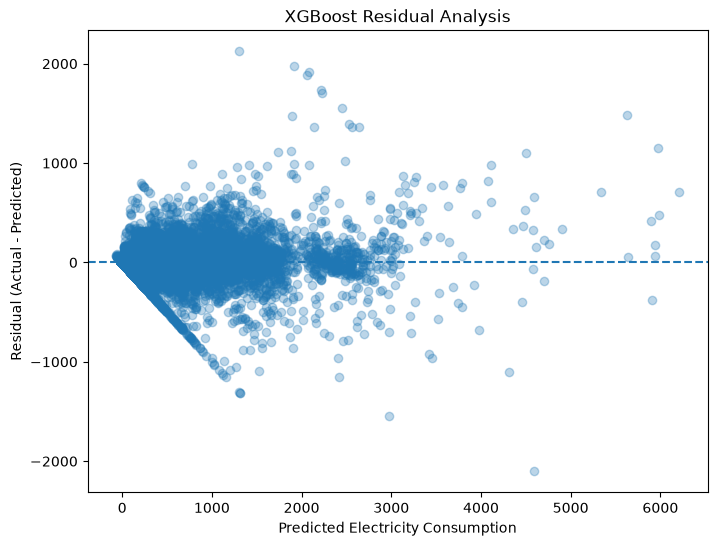

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_pred_xgb, residuals_xgb, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Electricity Consumption")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("XGBoost Residual Analysis")

plt.show()

In [60]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.6.0


In [61]:
from lightgbm import LGBMRegressor

# Create LightGBM model
lgb_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# Train the model
lgb_model.fit(
    X_train,
    y_train
)

print("LightGBM model training completed!")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011301 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1425
[LightGBM] [Info] Number of data points in the train set: 800000, number of used features: 16
[LightGBM] [Info] Start training from score 138.576623
LightGBM model training completed!


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred_lgb = lgb_model.predict(X_test)

# Calculate metrics
mae_lgb = mean_absolute_error(y_test, y_pred_lgb)

rmse_lgb = np.sqrt(
    mean_squared_error(y_test, y_pred_lgb)
)

r2_lgb = r2_score(y_test, y_pred_lgb)

print("LightGBM Model Performance")
print("-" * 40)

print(f"MAE:  {mae_lgb:.4f}")
print(f"RMSE: {rmse_lgb:.4f}")
print(f"R² Score: {r2_lgb:.4f}")

LightGBM Model Performance
----------------------------------------
MAE:  48.7151
RMSE: 86.6767
R² Score: 0.8858


In [63]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "MAE": [
        mae_rf,
        mae_xgb,
        mae_lgb
    ],
    "RMSE": [
        rmse_rf,
        rmse_xgb,
        rmse_lgb
    ],
    "R2 Score": [
        r2_rf,
        r2_xgb,
        r2_lgb
    ]
})

# Sort by RMSE - lower is better
model_results = model_results.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("MODEL COMPARISON")
print("=" * 60)

print(model_results)

MODEL COMPARISON
           Model        MAE       RMSE  R2 Score
0  Random Forest  16.001618  43.728307  0.970945
1        XGBoost  24.017571  52.541599  0.958053
2       LightGBM  48.715140  86.676733  0.885845


In [64]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
print("=" * 50)
print(feature_importance)

FEATURE IMPORTANCE
              Feature  Importance
3                 sqm    0.547238
0         building_id    0.247319
2   primaryspaceusage    0.064630
1             site_id    0.032972
4      airTemperature    0.027624
10               hour    0.018819
12              month    0.016936
6      dewTemperature    0.012617
14               year    0.011407
11        day_of_week    0.004270
7      seaLvlPressure    0.004265
13                day    0.003446
15         is_weekend    0.002429
5       cloudCoverage    0.002338
8       windDirection    0.002122
9           windSpeed    0.001569


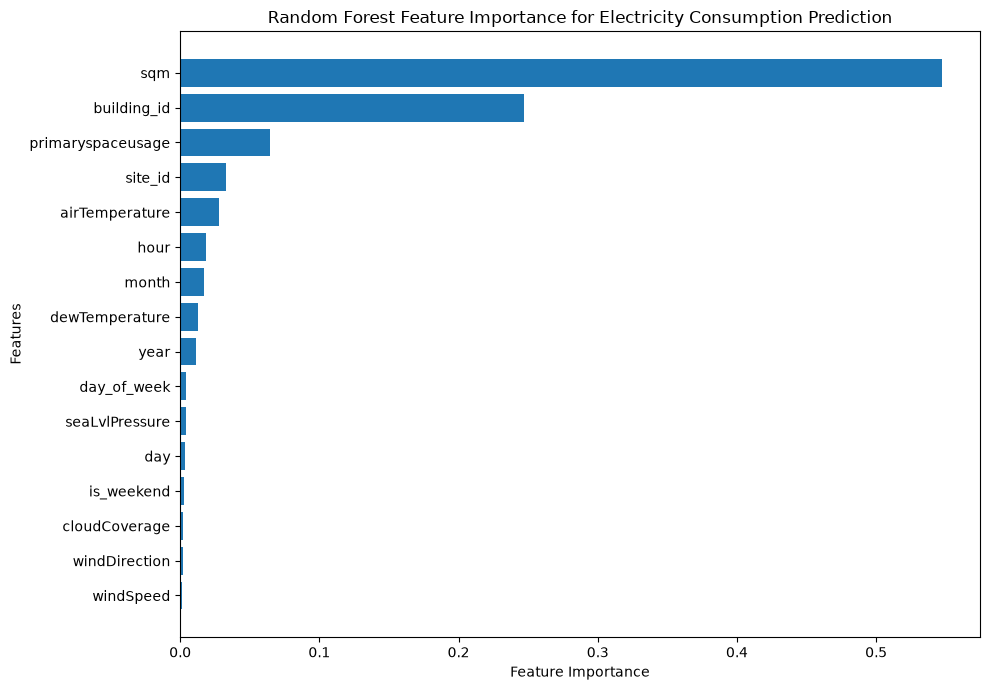

In [65]:
import matplotlib.pyplot as plt

# Sort for horizontal bar chart
feature_importance_plot = feature_importance.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_plot["Feature"],
    feature_importance_plot["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance for Electricity Consumption Prediction")

plt.tight_layout()
plt.show()

In [66]:
import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Random Forest model
joblib.dump(
    rf_model,
    "../models/random_forest_energy_model.pkl"
)

# Save label encoders
joblib.dump(
    label_encoders,
    "../models/label_encoders.pkl"
)

# Save feature names/order
joblib.dump(
    list(X_train.columns),
    "../models/feature_columns.pkl"
)

print("Final model and preprocessing files saved successfully!")

Final model and preprocessing files saved successfully!


In [67]:
import joblib

# Load saved files
loaded_model = joblib.load(
    "../models/random_forest_energy_model.pkl"
)

loaded_encoders = joblib.load(
    "../models/label_encoders.pkl"
)

loaded_features = joblib.load(
    "../models/feature_columns.pkl"
)

print("Model loaded successfully!")
print("Number of features:", len(loaded_features))
print("Features:")
print(loaded_features)

Model loaded successfully!
Number of features: 16
Features:
['building_id', 'site_id', 'primaryspaceusage', 'sqm', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'seaLvlPressure', 'windDirection', 'windSpeed', 'hour', 'day_of_week', 'month', 'day', 'year', 'is_weekend']


In [68]:
# Take 5 sample records from the test set
sample_X = X_test.head(5)

# Actual electricity consumption
sample_actual = y_test.head(5)

# Predict using the loaded model
sample_predictions = loaded_model.predict(sample_X)

# Create comparison table
prediction_results = pd.DataFrame({
    "Actual Consumption": sample_actual.values,
    "Predicted Consumption": sample_predictions
})

print("SAMPLE PREDICTION RESULTS")
print("=" * 50)

print(prediction_results)

SAMPLE PREDICTION RESULTS
   Actual Consumption  Predicted Consumption
0            191.3220             190.821463
1             23.0404              14.132721
2             10.3000              10.368621
3             24.6400              19.840054
4            538.3300             545.099052


In [69]:
import pandas as pd

def predict_energy(input_data):
    """
    Predict electricity consumption from raw input data.
    """

    # Convert input dictionary to DataFrame
    input_df = pd.DataFrame([input_data])

    # Encode categorical columns
    categorical_columns = [
        "building_id",
        "site_id",
        "primaryspaceusage"
    ]

    for column in categorical_columns:
        input_df[column] = loaded_encoders[column].transform(
            input_df[column]
        )

    # Ensure correct feature order
    input_df = input_df[loaded_features]

    # Make prediction
    prediction = loaded_model.predict(input_df)

    return prediction[0]


print("Prediction function created successfully!")

Prediction function created successfully!


In [70]:
# Example raw input

sample_input = {
    "building_id": "Bear_education_Elise",
    "site_id": "Bear",
    "primaryspaceusage": "Education",
    "sqm": 20664.8,
    "airTemperature": 20.0,
    "cloudCoverage": 2.0,
    "dewTemperature": 13.3,
    "seaLvlPressure": 1017.3,
    "windDirection": 300.0,
    "windSpeed": 6.7,
    "hour": 15,
    "day_of_week": 5,
    "month": 9,
    "day": 10,
    "year": 2016,
    "is_weekend": 1
}

predicted_energy = predict_energy(sample_input)

print(
    f"Predicted Electricity Consumption: "
    f"{predicted_energy:.2f}"
)

Predicted Electricity Consumption: 176.35


In [71]:
def optimize_energy(predicted_demand, available_solar):
    
    # Solar energy cannot exceed electricity demand
    solar_used = min(predicted_demand, available_solar)
    
    # Remaining demand comes from the grid
    grid_required = max(predicted_demand - solar_used, 0)
    
    # Calculate percentages
    solar_percentage = (
        solar_used / predicted_demand * 100
        if predicted_demand > 0 else 0
    )
    
    grid_percentage = (
        grid_required / predicted_demand * 100
        if predicted_demand > 0 else 0
    )
    
    return {
        "predicted_demand": predicted_demand,
        "solar_available": available_solar,
        "solar_used": solar_used,
        "grid_required": grid_required,
        "solar_percentage": solar_percentage,
        "grid_percentage": grid_percentage
    }


print("Energy optimization function created successfully!")

Energy optimization function created successfully!


In [72]:
# Example energy optimization test

predicted_demand = 176.35
available_solar = 80.0

optimization_result = optimize_energy(
    predicted_demand,
    available_solar
)

print("ENERGY OPTIMIZATION RESULT")
print("=" * 50)

for key, value in optimization_result.items():
    print(f"{key}: {value:.2f}")

ENERGY OPTIMIZATION RESULT
predicted_demand: 176.35
solar_available: 80.00
solar_used: 80.00
grid_required: 96.35
solar_percentage: 45.36
grid_percentage: 54.64


In [73]:
# Check actual solar generation data

solar_records = master_data[
    master_data["solar_generation"].notna()
][[
    "timestamp",
    "building_id",
    "electricity_consumption",
    "solar_generation"
]]

print("Solar records shape:", solar_records.shape)

print("\nFirst 10 solar records:")
print(solar_records.head(10))

Solar records shape: (66218, 4)

First 10 solar records:
                   timestamp               building_id  \
18419716 2016-01-01 00:00:00  Bobcat_education_Coleman   
18419717 2016-01-01 01:00:00  Bobcat_education_Coleman   
18419718 2016-01-01 02:00:00  Bobcat_education_Coleman   
18419719 2016-01-01 03:00:00  Bobcat_education_Coleman   
18419720 2016-01-01 04:00:00  Bobcat_education_Coleman   
18419721 2016-01-01 05:00:00  Bobcat_education_Coleman   
18419722 2016-01-01 06:00:00  Bobcat_education_Coleman   
18419723 2016-01-01 07:00:00  Bobcat_education_Coleman   
18419724 2016-01-01 08:00:00  Bobcat_education_Coleman   
18419725 2016-01-01 09:00:00  Bobcat_education_Coleman   

          electricity_consumption  solar_generation  
18419716                  92.1202              0.37  
18419717                  87.0000              0.39  
18419718                  85.2501              0.39  
18419719                  83.7502              0.38  
18419720                  83.5001 

In [74]:
# Select one example record with solar data
example_row = solar_records.iloc[9]

actual_demand = example_row["electricity_consumption"]
actual_solar = example_row["solar_generation"]

# Run optimization
actual_optimization = optimize_energy(
    actual_demand,
    actual_solar
)

print("ACTUAL SOLAR OPTIMIZATION TEST")
print("=" * 50)

print("Timestamp:", example_row["timestamp"])
print("Building:", example_row["building_id"])
print()

for key, value in actual_optimization.items():
    print(f"{key}: {value:.2f}")

ACTUAL SOLAR OPTIMIZATION TEST
Timestamp: 2016-01-01 09:00:00
Building: Bobcat_education_Coleman

predicted_demand: 107.13
solar_available: 4.90
solar_used: 4.90
grid_required: 102.23
solar_percentage: 4.57
grid_percentage: 95.43


In [76]:
# Select the example row
example_index = 18419725

# Get complete row from master_data
example_data = master_data.loc[example_index]

# Create DataFrame with the 16 model features
model_input = pd.DataFrame(
    [example_data[loaded_features]]
)

# Encode categorical columns
categorical_columns = [
    "building_id",
    "site_id",
    "primaryspaceusage"
]

for column in categorical_columns:
    model_input[column] = loaded_encoders[column].transform(
        model_input[column]
    )

# Ensure correct feature order
model_input = model_input[loaded_features]

# Predict electricity demand
predicted_demand = loaded_model.predict(model_input)[0]

# Get actual solar generation
available_solar = example_data["solar_generation"]

# Run optimization
final_optimization = optimize_energy(
    predicted_demand,
    available_solar
)

print("FINAL ML + SOLAR OPTIMIZATION")
print("=" * 55)

print("Timestamp:", example_data["timestamp"])
print("Building:", example_data["building_id"])

print("\nActual Electricity Consumption:",
      round(example_data["electricity_consumption"], 2))

print("Predicted Electricity Demand:",
      round(predicted_demand, 2))

print("Available Solar Generation:",
      round(available_solar, 2))

print("\nOPTIMIZED ENERGY ALLOCATION")
print("-" * 55)

print("Solar Used:",
      round(final_optimization["solar_used"], 2))

print("Grid Required:",
      round(final_optimization["grid_required"], 2))

print("Solar Percentage:",
      round(final_optimization["solar_percentage"], 2), "%")

print("Grid Percentage:",
      round(final_optimization["grid_percentage"], 2), "%")

FINAL ML + SOLAR OPTIMIZATION
Timestamp: 2016-01-01 09:00:00
Building: Bobcat_education_Coleman

Actual Electricity Consumption: 107.13
Predicted Electricity Demand: 165.97
Available Solar Generation: 4.9

OPTIMIZED ENERGY ALLOCATION
-------------------------------------------------------
Solar Used: 4.9
Grid Required: 161.07
Solar Percentage: 2.95 %
Grid Percentage: 97.05 %


In [77]:
def run_energy_pipeline(example_data):
    
    # -----------------------------
    # 1. Prepare model input
    # -----------------------------
    model_input = pd.DataFrame(
        [example_data[loaded_features]]
    )
    
    # -----------------------------
    # 2. Encode categorical columns
    # -----------------------------
    categorical_columns = [
        "building_id",
        "site_id",
        "primaryspaceusage"
    ]
    
    for column in categorical_columns:
        model_input[column] = loaded_encoders[column].transform(
            model_input[column]
        )
    
    # Ensure correct feature order
    model_input = model_input[loaded_features]
    
    # -----------------------------
    # 3. Predict electricity demand
    # -----------------------------
    predicted_demand = loaded_model.predict(
        model_input
    )[0]
    
    # -----------------------------
    # 4. Get solar availability
    # -----------------------------
    available_solar = example_data["solar_generation"]
    
    # Handle missing solar data
    if pd.isna(available_solar):
        available_solar = 0.0
    
    # -----------------------------
    # 5. Optimize energy allocation
    # -----------------------------
    optimization = optimize_energy(
        predicted_demand,
        available_solar
    )
    
    # -----------------------------
    # 6. Return complete result
    # -----------------------------
    return {
        "timestamp": example_data["timestamp"],
        "building_id": example_data["building_id"],
        "predicted_demand": predicted_demand,
        "solar_available": available_solar,
        "solar_used": optimization["solar_used"],
        "grid_required": optimization["grid_required"],
        "solar_percentage": optimization["solar_percentage"],
        "grid_percentage": optimization["grid_percentage"]
    }


print("Complete energy pipeline created successfully!")

Complete energy pipeline created successfully!


In [78]:
# Test the complete pipeline
example_data = master_data.loc[18419725]

pipeline_result = run_energy_pipeline(example_data)

print("COMPLETE ENERGY PIPELINE RESULT")
print("=" * 55)

for key, value in pipeline_result.items():
    if isinstance(value, (int, float, np.number)):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

COMPLETE ENERGY PIPELINE RESULT
timestamp: 2016-01-01 09:00:00
building_id: Bobcat_education_Coleman
predicted_demand: 165.97
solar_available: 4.90
solar_used: 4.90
grid_required: 161.07
solar_percentage: 2.95
grid_percentage: 97.05


In [79]:
import joblib

# Save XGBoost model
joblib.dump(xgb_model, "xgboost_model.pkl")

# Save LightGBM model
joblib.dump(lgb_model, "lightgbm_model.pkl")

print("XGBoost and LightGBM models saved successfully!")

XGBoost and LightGBM models saved successfully!


In [81]:
# Check likely model variable names

possible_models = [
    "xgb_model",
    "xgboost_model",
    "lgb_model",
    "lightgbm_model"
]

for name in possible_models:
    if name in globals():
        print(f"FOUND: {name}")
    else:
        print(f"Not found: {name}")

FOUND: xgb_model
Not found: xgboost_model
FOUND: lgb_model
Not found: lightgbm_model


In [82]:
import joblib

joblib.dump(xgb_model, "xgboost_model.pkl")
joblib.dump(lgb_model, "lightgbm_model.pkl")

print("XGBoost and LightGBM models saved successfully!")

XGBoost and LightGBM models saved successfully!


In [84]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nPKL files available:")
for file in os.listdir():
    if file.endswith(".pkl"):
        print(file)

Current working directory:
d:\AIRenewableEnergyOptimization\notebooks

PKL files available:
lightgbm_model.pkl
xgboost_model.pkl


In [85]:
possible_rf_models = [
    "random_forest_model",
    "rf_model",
    "model",
    "loaded_model"
]

for name in possible_rf_models:
    if name in globals():
        print(f"FOUND: {name}")
    else:
        print(f"Not found: {name}")

Not found: random_forest_model
FOUND: rf_model
Not found: model
FOUND: loaded_model


In [86]:
import joblib

joblib.dump(rf_model, "random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [87]:
import os

print("PKL files available:")

for file in os.listdir():
    if file.endswith(".pkl"):
        print(file)

PKL files available:
lightgbm_model.pkl
random_forest_model.pkl
xgboost_model.pkl


In [88]:
import joblib

# Load all three trained models
rf_model = joblib.load("random_forest_model.pkl")

xgb_model = joblib.load("xgboost_model.pkl")

lgb_model = joblib.load("lightgbm_model.pkl")

print("All three models loaded successfully!")

print("\nAvailable models:")
print("1. Random Forest")
print("2. XGBoost")
print("3. LightGBM")

All three models loaded successfully!

Available models:
1. Random Forest
2. XGBoost
3. LightGBM


In [89]:
def compare_model_predictions(example_data):
    
    # ---------------------------------
    # 1. Prepare input features
    # ---------------------------------
    model_input = pd.DataFrame(
        [example_data[loaded_features]]
    )
    
    # ---------------------------------
    # 2. Encode categorical features
    # ---------------------------------
    categorical_columns = [
        "building_id",
        "site_id",
        "primaryspaceusage"
    ]
    
    for column in categorical_columns:
        model_input[column] = loaded_encoders[column].transform(
            model_input[column]
        )
    
    # Ensure feature order is correct
    model_input = model_input[loaded_features]
    
    # ---------------------------------
    # 3. Get predictions from all models
    # ---------------------------------
    rf_prediction = rf_model.predict(model_input)[0]
    
    xgb_prediction = xgb_model.predict(model_input)[0]
    
    lgb_prediction = lgb_model.predict(model_input)[0]
    
    # ---------------------------------
    # 4. Return all predictions
    # ---------------------------------
    return {
        "random_forest": rf_prediction,
        "xgboost": xgb_prediction,
        "lightgbm": lgb_prediction
    }


print("Three-model prediction function created successfully!")

Three-model prediction function created successfully!


In [90]:
example_data = master_data.loc[18419725]

model_predictions = compare_model_predictions(example_data)

print("THREE-MODEL PREDICTION RESULTS")
print("=" * 50)

for model, prediction in model_predictions.items():
    print(f"{model}: {prediction:.2f}")

THREE-MODEL PREDICTION RESULTS
random_forest: 165.97
xgboost: 144.89
lightgbm: 132.76


In [91]:
def select_best_prediction(model_predictions):
    
    # Model performance from our experiments
    model_performance = {
        "random_forest": {
            "MAE": 16.001618,
            "RMSE": 43.728307,
            "R2": 0.970945
        },
        "xgboost": {
            "MAE": 24.017571,
            "RMSE": 52.541599,
            "R2": 0.958053
        },
        "lightgbm": {
            "MAE": 48.715140,
            "RMSE": 86.676733,
            "R2": 0.885845
        }
    }
    
    # Select best model based on:
    # Lowest MAE as primary criterion
    best_model = min(
        model_performance,
        key=lambda model: model_performance[model]["MAE"]
    )
    
    final_prediction = model_predictions[best_model]
    
    return {
        "recommended_model": best_model,
        "final_prediction": final_prediction,
        "model_performance": model_performance
    }


print("Model selection function created successfully!")

Model selection function created successfully!


In [92]:
model_decision = select_best_prediction(model_predictions)

print("MODEL DECISION")
print("=" * 50)

print("Recommended Model:",
      model_decision["recommended_model"])

print("Final Predicted Demand:",
      round(model_decision["final_prediction"], 2))

MODEL DECISION
Recommended Model: random_forest
Final Predicted Demand: 165.97


In [93]:
def run_complete_energy_pipeline(example_data):
    
    # ==========================================
    # 1. GET PREDICTIONS FROM ALL THREE MODELS
    # ==========================================
    
    model_predictions = compare_model_predictions(example_data)
    
    
    # ==========================================
    # 2. SELECT BEST MODEL BASED ON PERFORMANCE
    # ==========================================
    
    model_decision = select_best_prediction(model_predictions)
    
    recommended_model = model_decision["recommended_model"]
    final_prediction = model_decision["final_prediction"]
    
    
    # ==========================================
    # 3. GET SOLAR AVAILABILITY
    # ==========================================
    
    available_solar = example_data["solar_generation"]
    
    # If solar data is missing
    if pd.isna(available_solar):
        available_solar = 0.0
    
    
    # ==========================================
    # 4. OPTIMIZE SOLAR + GRID ALLOCATION
    # ==========================================
    
    optimization = optimize_energy(
        final_prediction,
        available_solar
    )
    
    
    # ==========================================
    # 5. RETURN COMPLETE RESULTS
    # ==========================================
    
    return {
        
        # Basic information
        "timestamp": example_data["timestamp"],
        "building_id": example_data["building_id"],
        
        
        # All model predictions
        "random_forest_prediction":
            model_predictions["random_forest"],
        
        "xgboost_prediction":
            model_predictions["xgboost"],
        
        "lightgbm_prediction":
            model_predictions["lightgbm"],
        
        
        # Model decision
        "recommended_model": recommended_model,
        "final_predicted_demand": final_prediction,
        
        
        # Energy optimization
        "solar_available": available_solar,
        "solar_used": optimization["solar_used"],
        "grid_required": optimization["grid_required"],
        "solar_percentage": optimization["solar_percentage"],
        "grid_percentage": optimization["grid_percentage"]
    }


print("Complete three-model energy pipeline created successfully!")

Complete three-model energy pipeline created successfully!


In [94]:
example_data = master_data.loc[18419725]

final_result = run_complete_energy_pipeline(example_data)

print("FINAL SMART ENERGY MANAGEMENT RESULT")
print("=" * 65)

for key, value in final_result.items():
    
    if isinstance(value, (int, float, np.number)):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

FINAL SMART ENERGY MANAGEMENT RESULT
timestamp: 2016-01-01 09:00:00
building_id: Bobcat_education_Coleman
random_forest_prediction: 165.97
xgboost_prediction: 144.89
lightgbm_prediction: 132.76
recommended_model: random_forest
final_predicted_demand: 165.97
solar_available: 4.90
solar_used: 4.90
grid_required: 161.07
solar_percentage: 2.95
grid_percentage: 97.05
